# **10.  Validación cruzada y optimización de hiperparámetros.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez


## 10.1 Preparación.

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

In [58]:
housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

X.shape

(20640, 8)

## 10.2 Reservamos el conjunto de prueba.

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state=42 
)


## 10.3 El problema de una única partición.

In [60]:
modelo = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.5,
    max_depth=2,
    random_state=42
)

In [61]:
resultados_split = []

for semilla in [1,10,42,100,500]:
    X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size = 0.20,
    random_state=semilla
    )

    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    resultados_split.append({"random_state": semilla, "RMSE": rmse})

df_split = pd.DataFrame(resultados_split)

df_split




,random_state,RMSE
0,1,0.515015
1,10,0.510848
2,42,0.514444
3,100,0.496784
4,500,0.503796


## 10.5 Nuestro primer Cross-Validation.

In [62]:
cv = KFold(n_splits=5,
           shuffle=True,
           random_state=42)

In [63]:
modelo = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

In [64]:
scores = cross_val_score(
    modelo,
    X_train,
    y_train,
    cv = cv,
    scoring="neg_root_mean_squared_error"
)

scores

array([-0.58945794, -0.56738891, -0.5513569 , -0.58885872, -0.56687094])

In [65]:
rmse_cv = -scores
rmse_cv

array([0.58945794, 0.56738891, 0.5513569 , 0.58885872, 0.56687094])

In [66]:
rmse_cv.mean()

np.float64(0.5727866831974053)

In [67]:
rmse_cv.std()

np.float64(0.01455753414363465)

In [68]:
print(
    f"RMSE CV: {rmse_cv.mean(): .4f}"
    f"++/- {rmse_cv.std():.4f}"
)

RMSE CV:  0.5728++/- 0.0146


In [69]:
cv

KFold(n_splits=5, random_state=42, shuffle=True)

## 10.6 Visualización de los folds.

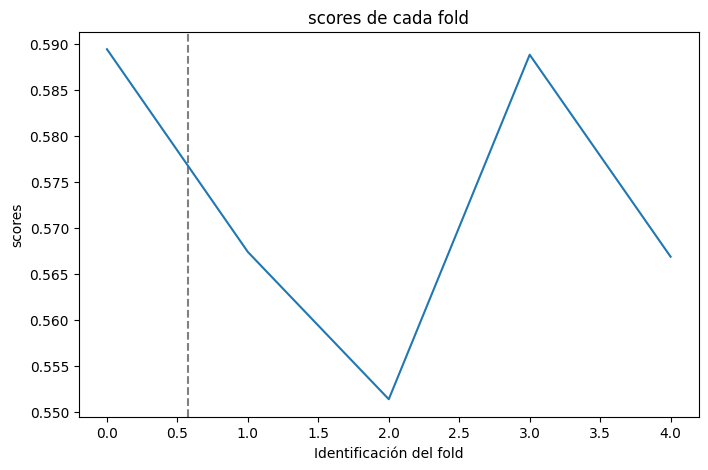

In [70]:
plt.figure(figsize=(8,5))

plt.axvline(x = rmse_cv.mean(), linestyle = "--", color = "gray")
plt.plot(rmse_cv)

plt.xlabel("Identificación del fold")
plt.ylabel("scores")
plt.title("scores de cada fold")
plt.show()

## 10.7 Comparando algunas configuraciones.

In [1]:
configuraciones = [
    ("A", 0.1, 100, 2),
    ("B", 0.05, 200, 2),
    ("C", 0.01, 500, 2),
    ("D", 0.1, 100, 4)
    ]

In [2]:
resultados_cv = []

for nombre, lr, n_est, depth in configuraciones:
    modelo = GradientBoostingRegressor(
        learning_rate = lr,
        n_estimators=n_est,
        max_depth=depth,
        random_state=42
    )

    scores = cross_val_score(
    modelo,
    X_train,
    y_train,
    cv = cv,
    scoring="neg_root_mean_squared_error"
    )

    rmse_cv = -scores
    resultados_cv.append(
        {
            "Modelo": nombre,
            "learning_rate": lr,
            "n_estimates": n_est,
            "max_depth": depth,
            "RMSE_CV": rmse_cv.mean(),
            "SD_CV": rmse_cv.std()
        }
    )

df_cv = pd.DataFrame(resultados_cv)
df_cv

NameError: name 'GradientBoostingRegressor' is not defined

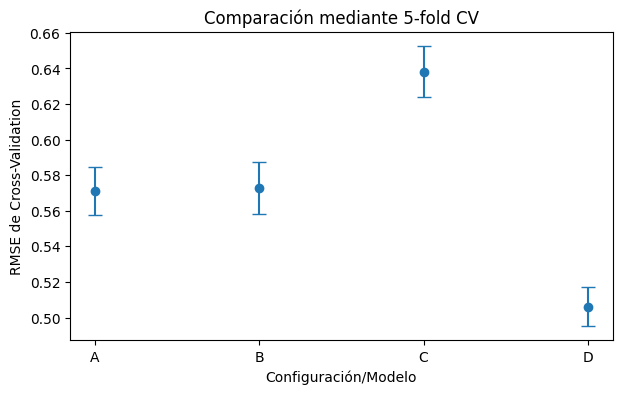

In [ ]:
plt.figure(figsize=(7,4))

plt.errorbar(
    df_cv["Modelo"],
    df_cv["RMSE_CV"],
    yerr = df_cv["SD_CV"],
    fmt = "o",
    capsize = 5
)

plt.xlabel("Configuración/Modelo")
plt.ylabel("RMSE de Cross-Validation")
plt.title("Comparación mediante 5-fold CV")
plt.show()

## 10.9 Grid Search.

In [ ]:
param_grid = {
    "learning_rate": [0.01, 0.05, 0.1],
    "n_estimators": [100, 200, 500],
    "max_depth": [2,3,4]
}

In [ ]:
modelo = GradientBoostingRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring = "neg_root_mean_squared_error",
    cv=cv,
    n_jobs = -1,
    return_train_score = True
)

In [ ]:
inicio = perf_counter()

grid_search.fit(X_train, y_train)

tiempo_grid = perf_counter() - inicio

print(f"Tiempo: {tiempo_grid:.2f} segundos")

Tiempo: 269.12 segundos


## 10.10 Resultados de Grid Search.

In [ ]:
grid_search.best_params_

{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 500}

In [ ]:
grid_search.best_score_

np.float64(-0.4712213097837922)

In [ ]:
best_rmse_grid = - grid_search.best_score_
best_rmse_grid

np.float64(0.4712213097837922)

In [ ]:
grid_search.best_estimator_

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",500
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

## 10.11 Todos los resultados de Grid Search.

In [ ]:
grid_search.cv_results_

{'mean_fit_time': array([ 5.78093257, 10.99570966, 28.6710165 ,  8.09284077, 16.03798413,
        44.70302105, 10.26842594, 28.48328567, 66.91357789,  6.10946102,
        12.18117943, 31.17266879, 10.73124309, 19.5410985 , 41.41762681,
        12.12816834, 22.30164919, 73.2254962 ,  6.04775801, 12.01946259,
        39.08455014, 18.22740598, 18.06969962, 49.98857064, 25.30868745,
        27.49889393, 41.60572662]),
 'std_fit_time': array([0.61894393, 1.06996287, 2.67246446, 0.8478746 , 1.94457031,
        3.44427831, 1.51168519, 1.65890542, 4.36195142, 2.33968653,
        1.16201911, 1.66905204, 2.30523041, 1.43500172, 3.44359753,
        1.63398327, 1.52364113, 8.88659504, 0.67316457, 3.17419061,
        0.98229355, 3.12847484, 4.23547127, 1.81747997, 0.22112258,
        5.01395717, 0.81380016]),
 'mean_score_time': array([0.0101182 , 0.01967216, 0.03007302, 0.01284261, 0.02348208,
        0.03762531, 0.02123013, 0.02719431, 0.05823746, 0.00762787,
        0.01600852, 0.03685617, 0.025

In [ ]:
result_grid = pd.DataFrame(
    grid_search.cv_results_   
)

result_grid.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_learning_rate,param_max_depth,param_n_estimators,params,split0_test_score,split1_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,5.780933,0.618944,0.010118,0.002367,0.01,2,100,"{'learning_rate': 0.01, 'max_depth': 2, 'n_est...",-0.887039,-0.876643,...,-0.871948,0.013399,27,-0.864676,-0.867930,-0.871145,-0.866046,-0.872341,-0.868428,0.002922
1,10.995710,1.069963,0.019672,0.013623,0.01,2,200,"{'learning_rate': 0.01, 'max_depth': 2, 'n_est...",-0.787626,-0.775844,...,-0.772103,0.014140,24,-0.763372,-0.765952,-0.769953,-0.762848,-0.769868,-0.766398,0.003054
2,28.671017,2.672464,0.030073,0.007075,0.01,2,500,"{'learning_rate': 0.01, 'max_depth': 2, 'n_est...",-0.652214,-0.641599,...,-0.638218,0.014304,21,-0.625263,-0.632007,-0.632197,-0.625285,-0.632295,-0.629410,0.003378
3,8.092841,0.847875,0.012843,0.002672,0.01,3,100,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",-0.827065,-0.814603,...,-0.811513,0.014723,26,-0.801785,-0.805551,-0.808537,-0.801470,-0.809128,-0.805294,0.003231
4,16.037984,1.944570,0.023482,0.007227,0.01,3,200,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",-0.714904,-0.698003,...,-0.698914,0.014884,23,-0.685792,-0.688181,-0.692062,-0.683577,-0.693336,-0.688589,0.003680


In [ ]:
columnas = [
    "param_learning_rate",
    "param_n_estimators",
    "param_max_depth",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
    "mean_fit_time"
]

In [ ]:
result_grid[columnas].head()

,param_learning_rate,param_n_estimators,param_max_depth,mean_test_score,std_test_score,rank_test_score,mean_fit_time
0,0.01,100,2,-0.871948,0.013399,27,5.780933
1,0.01,200,2,-0.772103,0.014140,24,10.995710
2,0.01,500,2,-0.638218,0.014304,21,28.671017
3,0.01,100,3,-0.811513,0.014723,26,8.092841
4,0.01,200,3,-0.698914,0.014884,23,16.037984


In [ ]:
result_grid["RMSE_CV"] = (-result_grid["mean_test_score"])

In [ ]:
result_grid[
    [
        "param_learning_rate",
        "param_n_estimators",
        "param_max_depth",
        "RMSE_CV",
        "std_test_score",
        "mean_fit_time"
    ]
].sort_values("RMSE_CV").head(10)

,param_learning_rate,param_n_estimators,param_max_depth,RMSE_CV,std_test_score,mean_fit_time
26,0.10,500,4,0.471221,0.010841,41.605727
17,0.05,500,4,0.480041,0.010797,73.225496
23,0.10,500,3,0.480491,0.012018,49.988571
25,0.10,200,4,0.485289,0.010716,27.498894
14,0.05,500,3,0.497992,0.011475,41.417627
22,0.10,200,3,0.504642,0.011120,18.069700
16,0.05,200,4,0.506160,0.010279,22.301649
24,0.10,100,4,0.506170,0.011069,25.308687
20,0.10,500,2,0.509492,0.010939,39.084550
11,0.05,500,2,0.528995,0.012282,31.172669


## 10.12 Visualizando una parte de la búsqueda.

In [ ]:
grid_depth2 = result_grid[result_grid["param_max_depth"]==2].copy()

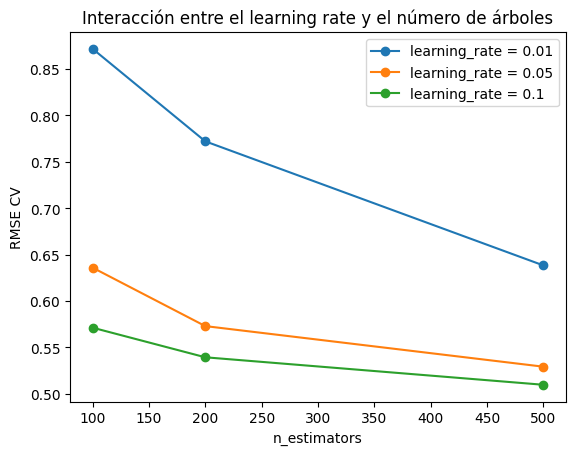

In [ ]:
for lr in sorted(grid_depth2["param_learning_rate"].unique()):
    datos = grid_depth2[grid_depth2["param_learning_rate"]==lr].sort_values("param_n_estimators")
    plt.plot(datos["param_n_estimators"],
             datos["RMSE_CV"],
             marker = "o",
             label = f"learning_rate = {lr}")


plt.xlabel("n_estimators")
plt.ylabel("RMSE CV")
plt.title("Interacción entre el learning rate y el número de árboles")
plt.legend()
plt.show()

## 10.14 Random Search.

In [ ]:
from scipy.stats import randint, loguniform, uniform

In [ ]:
param_distributions = {
    "n_estimators": randint(100, 601),
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(1,6),
    "subsample": uniform(0.6, 0.4)
}

## 10.15 RandomizedSearchCV.

In [ ]:
random_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_distributions= param_distributions,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv= cv,
    random_state=42,
    n_jobs = -1,
    return_train_score=True
)


In [ ]:
inicio = perf_counter()

random_search.fit(X_train, y_train)

tiempo_random = perf_counter() - inicio

print(f"Tiempo: {tiempo_random:.2f} segundos")

KeyboardInterrupt: 

## 10.16 Resultados de Random Search.

In [ ]:
random_search.best_params_

{'learning_rate': np.float64(0.07027897634919636),
 'max_depth': 5,
 'n_estimators': 357,
 'subsample': np.float64(0.8887995089067299)}

In [ ]:
best_rmse_random = - random_search.best_score_
best_rmse_random

np.float64(0.4677347223500803)

## 10.18 ¿Y XGBoost?

In [ ]:
from xgboost import XGBRegressor

In [ ]:
xgb = XGBRegressor(
    objetive = "reg: squarederror",
    random_state = 42,
    n_jobs = -1
)

In [ ]:
param_xgb = {
    "n_estimators": [100, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2,3,5],
    "subsample": [0.7, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.9, 1.0]
}

## 10.20 Pipelines.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

In [ ]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

In [ ]:
scores_ridge = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv = cv,
    scoring="neg_root_mean_squared_error"
)

rmse_ridge = -scores_ridge

print(rmse_ridge.mean())

0.7205090731464324


In [ ]:
rmse_ridge.std()

np.float64(0.013894835993912027)

## 10.21 Tuning dentro de un Pipeline.

In [ ]:
param_grid_ridge = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

In [ ]:
grid_ridge = GridSearchCV(
    estimator=pipeline,
    param_grid= param_grid_ridge,
    cv = cv,
    scoring = "neg_root_mean_squared_error",
    n_jobs = -1
)

grid_ridge.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls

In [ ]:
grid_ridge.best_params_

{'model__alpha': 1}

In [ ]:
- grid_ridge.best_score_

np.float64(0.7205090731464324)

## 10.22 ¿Qué ocurre después de la búsqueda?

In [ ]:
grid_search.refit

True

In [ ]:
modelo_seleccionado = grid_search.best_estimator_
modelo_seleccionado

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",500
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

## Ejercicio.

Utiliza RandomizedSearchCV para explorar un modelo de Gradient Boosting con el mismo conjunto de datos usados.

Considera:

In [95]:
param_ejercicio = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [1, 2, 3, 4],
    "subsample": [0.7, 0.8, 0.9, 1.0]
}

Realiza una búsqueda de solamente 15 configuraciones utilizando 5-fold Cross-Validation.

Completa:

In [98]:
busqueda = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_distributions=param_ejercicio,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=1,
    return_train_score=True
)

In [100]:
busqueda.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.03, ...], 'max_depth': [1, 2, ...], 'n_estimators': [100, 200, ...], 'subsample': [0.7, 0.8, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that wou

Después:

- muestra los hiperparámetros seleccionados;

In [101]:
busqueda.best_params_

{'subsample': 0.8, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05}

- reporta el RMSE promedio de Cross-Validation;

In [102]:
- busqueda.best_score_

np.float64(0.49231818768889457)

- construye un DataFrame con las 15 configuraciones;
- ordénalas de menor a mayor RMSE;
- muestra las cinco primeras.

In [105]:
resultados_ejercicio = pd.DataFrame(
    busqueda.cv_results_
)

resultados_ejercicio["RMSE_CV"] = (
    -resultados_ejercicio["mean_test_score"])

In [106]:
resultados_ejercicio[
    [
        "param_learning_rate",
        "param_n_estimators",
        "param_max_depth",
        "param_subsample",
        "RMSE_CV",
        "mean_fit_time"
    ]
].sort_values("RMSE_CV").head(5)

,param_learning_rate,param_n_estimators,param_max_depth,param_subsample,RMSE_CV,mean_fit_time
5,0.05,300,4,0.8,0.492318,13.300173
0,0.10,200,3,0.7,0.505559,3.373165
10,0.05,200,4,0.7,0.505833,5.293300
6,0.10,100,4,0.9,0.505860,3.542863
12,0.10,200,3,0.9,0.507035,4.456591


Finalmente responde:

¿Cuántas configuraciones contiene el espacio completo?

$4^{4}$

¿Cuántos ajustes serían necesarios si utilizáramos Grid Search con 5-fold CV?

$4^{4} * 5$

¿Cuántos ajustes principales realizamos utilizando n_iter=15?

$ 15 * 5$

¿Por qué Random Search puede resultar útil cuando aumentamos el número de hiperparámetros?

Porque es menos costoso computacionalmente.